# Yield per µJ vs GMD: why do the low GMD bins give more electrons per µJ?

In `undulator_scan_aggregates.ipynb` the fast electrons per µJ (hits in `HIGH_KE` / mean GMD of a cell) fall by 2-3x
from the lowest to the highest GMD bin at every photon energy, while hits against GMD look like a straight line.
A straight line with an intercept, hits = a·G + b, gives hits / G = a + b / G, so both can be true at once. This
notebook goes back to the single shots of one combined file and checks where the difference comes from:

1. **The effect** from single shots, for the fast electrons, a slow-electron window and the ions.
2. **Background**: hits in the bunch slot without an FEL pulse.
3. **GMD noise**: hall against tunnel GMD, pulse by pulse. Binning on a noisy reading puts the pulses it under-reads
   into the lowest bins.
4. **Dead time**: hit spacing, hits per shot against a Poisson distribution, and the zero-hit yield −ln P(0), which
   dead time does not change.
5. **A third monitor**: the VLS line sum against the GMD, and as the normaliser.
6. **Photon-energy selection**: the aggregates keep only shots with a measured photon energy.
7. **Train position**: yield per µJ along the bunch train at fixed pulse energy.
8. **Step by step**: the per-µJ curve with each of these taken out.

**Data**: a combined file (`write_h5.py`, with the `photon_energy/` group from `photon_energy.py`) and the raw FLASH
files of the same run for the tunnel GMD (`/FL2/Photon Diagnostic/GMD/Pulse resolved energy/energy tunnel`,
channel 0; the combined `gmd` is the same dataset for the hall GMD). Everything is plain numpy arrays of shape
`(n_trains, n_pulses)`: `G` hall GMD, `T` tunnel GMD (scaled to hall µJ), `V` VLS line sum, `N[window]` hits per shot.

In [1]:
# ---- Parameters ---------------------------------------------------------------
COMBINED_H5 = 'run60611_AcH_undulator_scan_265-280eV_2809702542.h5'   # relative to config.COMBINED_DIR, or absolute
RUN = 60611                    # raw FLASH run of the same trains (tunnel GMD)
# COMBINED_H5, RUN = 'run60612_AcH_undulator_scan_part2_265-280eV_2809782740.h5', 60612
# COMBINED_H5, RUN = 'run60591_Ethanol_quick_undulator_scan_265-272eV_2808989151.h5', 60591

BUNCH_RANGE = (0, 100)         # slots with FEL pulses, half-open
EMPTY_SLOT = 100               # slot without an FEL pulse: background
WINDOWS = {                    # name: (axis, low, high); 'ke' in eV for electrons, 'mq' in u/e for ions
    'fast e': ('ke', 210, 285),    # HIGH_KE of undulator_scan_aggregates
    'slow e': ('ke', 10, 40),      # REF_KE
    'ions': ('mq', 0.5, 60),
}
GMD_MIN = 0.02                 # µJ, lowest hall GMD binned (as in the aggregates)
N_BINS = 20                    # hall GMD bins with equal numbers of shots
REF_BIN = 10                   # per-µJ curves are divided by their value in this bin
DT_TRAINS = (2000, 6000)       # trains used for the hit-spacing and fast-peak plots (section 4)
POS_G = (0.2, 0.5)             # µJ (tunnel, in hall µJ): pulse energies compared along the train (section 7)
CHUNK = 1000                   # trains per read

In [2]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import sys
import warnings

import h5py
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'analysis' / 'scripts' / 'config.py').exists())
sys.path.insert(0, str(REPO_ROOT / 'analysis' / 'scripts'))
import calibration
import config

for msg in ('invalid value encountered', 'divide by zero', 'Mean of empty slice'):
    warnings.filterwarnings('ignore', message=msg)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
TDC_PER_NS = 10                # TDC units (100 ps) per ns

## Load

Hits per shot are counted in each window from `tofs_e` / `tofs_i`, converting every hit with `calibration.py`.
`V` is `photon_energy/vls_window_sum` (ADU in a window around the line, pedestal and common mode subtracted) minus
`dark_median`, what the same estimator gives on the dark slot.

In [3]:
h5_path = Path(COMBINED_H5)
h5_path = h5_path if h5_path.is_absolute() else config.COMBINED_DIR / h5_path
with h5py.File(h5_path, 'r') as f:
    tID = f['tID'][:]
    gmd_all = f['gmd'][:]
    vws_all = f['photon_energy/vls_window_sum'][:] - f['photon_energy'].attrs['dark_median']
    pe_all = f['photon_energy/measured'][:]
    counts_all = {k: np.zeros(gmd_all.shape, np.int16) for k in WINDOWS}
    for s in range(0, len(tID), CHUNK):
        te = f['tofs_e'][s:s + CHUNK].astype(np.float32) / TDC_PER_NS     # ns, 0 = padding
        ti = f['tofs_i'][s:s + CHUNK].astype(np.float32) / TDC_PER_NS
        x = {'ke': calibration.ke_of_tof(np.where(te > 0, te, np.nan)),
             'mq': calibration.mq_of_tof(np.where(ti > 0, ti, np.nan))}
        for k, (axis, lo, hi) in WINDOWS.items():
            counts_all[k][s:s + CHUNK] = ((x[axis] >= lo) & (x[axis] < hi)).sum(-1)

b0, b1 = BUNCH_RANGE
G = gmd_all[:, b0:b1].astype(float)                                 # hall GMD (µJ)
N = {k: c[:, b0:b1].astype(float) for k, c in counts_all.items()}   # hits per shot in each window
N_empty = {k: c[:, EMPTY_SLOT].astype(float) for k, c in counts_all.items()}
V = vws_all[:, b0:b1].astype(float)                                 # VLS line sum (ADU)
pe = pe_all[:, b0:b1]                                               # measured photon energy (eV), NaN = none
print(f'{h5_path.name}: {len(tID)} trains x {b1 - b0} pulses')

run60611_AcH_undulator_scan_265-280eV_2809702542.h5: 76668 trains x 100 pulses


In [4]:
def raw_pulse_gmd(name, run=RUN):
    # pulse-resolved GMD intensity (channel 0) from the raw files of a run, on our train axis (NaN = missing)
    key = '/FL2/Photon Diagnostic/GMD/Pulse resolved energy/' + name
    out = np.full((len(tID), 100), np.nan)
    for p in sorted(config.RAW_H5_DIR.glob(f'*run{run}_*.h5')):
        with h5py.File(p, 'r') as f:
            idx = f[key + '/index'][:]
            val = f[key + '/value'][:, 0, :]
        pos = np.clip(np.searchsorted(tID, idx), 0, len(tID) - 1)
        hit = tID[pos] == idx
        out[pos[hit]] = val[hit]
    return out[:, b0:b1]


hall_raw = raw_pulse_gmd('energy hall')
T_raw = raw_pulse_gmd('energy tunnel')
both = np.isfinite(G) & np.isfinite(T_raw)
k_tun = np.sum(G[both] * T_raw[both]) / np.sum(T_raw[both] ** 2)
T = k_tun * T_raw                                                   # tunnel GMD in hall µJ
same = np.isfinite(G) & np.isfinite(hall_raw)
print(f'combined gmd vs raw hall GMD: max |difference| {np.max(np.abs(G[same] - hall_raw[same])):.2g} µJ')
print(f'tunnel GMD on {np.isfinite(T).mean():.1%} of pulses; hall = {k_tun:.3f} x tunnel (fit through zero), '
      f'correlation {np.corrcoef(G[both], T[both])[0, 1]:.4f}')

combined gmd vs raw hall GMD: max |difference| 0 µJ


tunnel GMD on 100.0% of pulses; hall = 0.664 x tunnel (fit through zero), correlation 0.9945


## 1. The effect, from single shots

Pulses with both GMDs and `G ≥ GMD_MIN`, in `N_BINS` hall-GMD bins with equal numbers of shots (the aggregates use 5
such bins). Left: hits per shot against the mean GMD of each bin, with a straight-line fit a·G + b. Right: hits per
µJ divided by their value in `REF_BIN`, with a + b / G from the fit dashed. A line through zero would be flat on the
right.

fast e  hits = 1.107 G + 0.2433   b / a = 0.220 µJ
slow e  hits = 0.297 G + 0.0077   b / a = 0.026 µJ
ions    hits = 2.279 G + 0.0209   b / a = 0.009 µJ


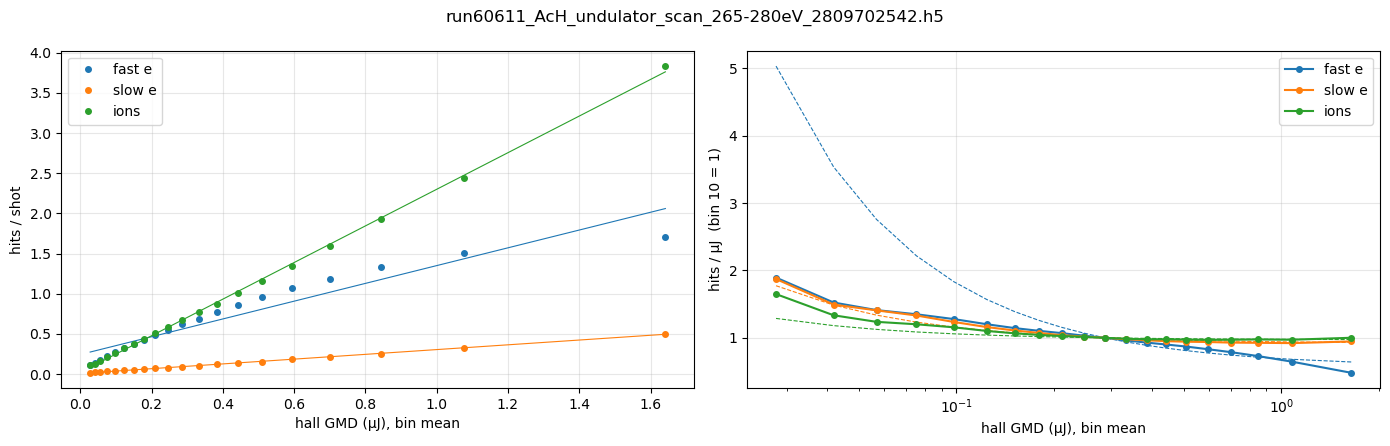

In [5]:
def binned(x, ys, sel, edges):
    # means of the arrays in ys over the shots in sel, in bins of x
    i = np.digitize(x[sel], edges[1:-1])
    n = np.bincount(i, minlength=len(edges) - 1)
    return [np.bincount(i, y[sel], len(edges) - 1) / n for y in ys]


sel = np.isfinite(G) & np.isfinite(T) & (G >= GMD_MIN)
edges = np.percentile(G[sel], np.linspace(0, 100, N_BINS + 1))
gb, gt = binned(G, [G, T], sel, edges)                              # mean hall / tunnel GMD per hall bin
nb = dict(zip(WINDOWS, binned(G, [N[k] for k in WINDOWS], sel, edges)))   # mean hits per shot per bin

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for j, k in enumerate(WINDOWS):
    a, b = np.polyfit(gb, nb[k], 1)
    print(f'{k:7s} hits = {a:.3f} G + {b:.4f}   b / a = {b / a:.3f} µJ')
    axs[0].plot(gb, nb[k], 'o', color=f'C{j}', ms=4, label=k)
    axs[0].plot(gb, a * gb + b, '-', color=f'C{j}', lw=0.8)
    r, m = nb[k] / gb, a + b / gb
    axs[1].plot(gb, r / r[REF_BIN], 'o-', color=f'C{j}', ms=4, label=k)
    axs[1].plot(gb, m / m[REF_BIN], '--', color=f'C{j}', lw=0.8)
axs[0].set(xlabel='hall GMD (µJ), bin mean', ylabel='hits / shot')
axs[1].set(xlabel='hall GMD (µJ), bin mean', ylabel=f'hits / µJ  (bin {REF_BIN} = 1)', xscale='log')
axs[0].legend()
axs[1].legend()
fig.suptitle(h5_path.name)
fig.tight_layout()
plt.show()

## 2. Background without a pulse

Hits per shot in the empty slot `EMPTY_SLOT`, next to all pulses and the pulses the hall GMD reads as (nearly) empty.

In [6]:
low = np.isfinite(G) & (G < 0.01)
for k in WINDOWS:
    print(f'{k:7s} empty slot {N_empty[k].mean():.1e} | all pulses {N[k][np.isfinite(G)].mean():.3f} | '
          f'hall GMD < 0.01 µJ: {N[k][low].mean():.3f}  hits / shot')
print(f'the {low.sum()} pulses with hall GMD < 0.01 µJ: mean hall {G[low].mean():+.4f} µJ, '
      f'mean tunnel {np.nanmean(T[low]):.4f} µJ')

fast e  empty slot 3.9e-05 | all pulses 0.662 | hall GMD < 0.01 µJ: 0.088  hits / shot
slow e  empty slot 1.2e-03 | all pulses 0.122 | hall GMD < 0.01 µJ: 0.013  hits / shot
ions    empty slot 1.2e-03 | all pulses 0.899 | hall GMD < 0.01 µJ: 0.084  hits / shot
the 159357 pulses with hall GMD < 0.01 µJ: mean hall -0.0003 µJ, mean tunnel 0.0363 µJ


## 3. Hall vs tunnel GMD

The tunnel GMD (upstream) sees the same pulses, so hall − tunnel is the single-shot reading noise of the two together.
Left: hall against tunnel, with the mean tunnel reading in each hall bin (red). Right: rms of hall − tunnel against
the pulse energy. Below: hits per µJ of the hall-binned shots, divided by the hall GMD (as the aggregates) and by the
tunnel GMD, whose noise is independent of the binning.

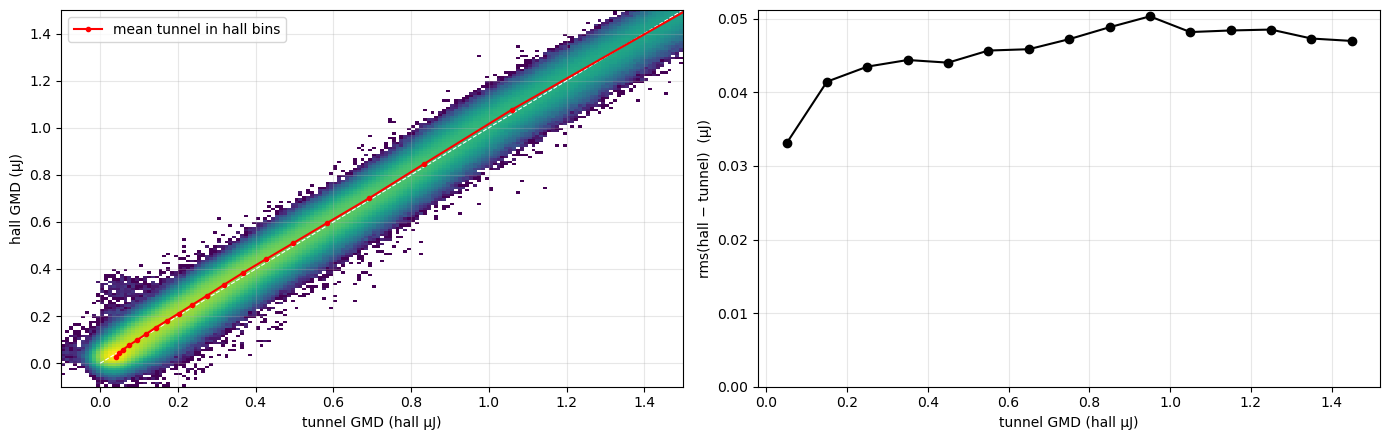

hall bin mean 0.028 µJ: tunnel mean 0.042 µJ
hall bin mean 0.042 µJ: tunnel mean 0.048 µJ
hall bin mean 0.057 µJ: tunnel mean 0.058 µJ
hall bin mean 0.075 µJ: tunnel mean 0.074 µJ
hall bin mean 0.098 µJ: tunnel mean 0.095 µJ


In [7]:
ok = np.isfinite(G) & np.isfinite(T)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].hist2d(T[ok], G[ok], bins=[np.linspace(-0.1, 1.5, 161)] * 2, norm=LogNorm(), cmap='viridis')
axs[0].plot([0, 1.5], [0, 1.5], 'w--', lw=0.8)
axs[0].plot(gt, gb, 'r.-', label='mean tunnel in hall bins')
axs[0].set(xlabel='tunnel GMD (hall µJ)', ylabel='hall GMD (µJ)')
axs[0].legend()
lv = np.linspace(0, 1.5, 16)
i = np.digitize(T[ok], lv)
rms = [(G[ok] - T[ok])[i == j].std() for j in range(1, len(lv))]
axs[1].plot(0.5 * (lv[1:] + lv[:-1]), rms, 'ko-')
axs[1].set(xlabel='tunnel GMD (hall µJ)', ylabel='rms(hall − tunnel)  (µJ)', ylim=(0, None))
fig.tight_layout()
plt.show()
for g, t in zip(gb[:5], gt[:5]):
    print(f'hall bin mean {g:.3f} µJ: tunnel mean {t:.3f} µJ')

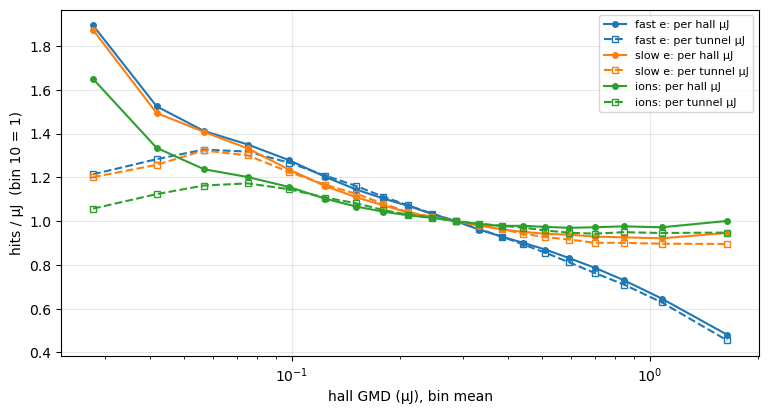

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for j, k in enumerate(WINDOWS):
    r_h, r_t = nb[k] / gb, nb[k] / gt
    ax.plot(gb, r_h / r_h[REF_BIN], 'o-', color=f'C{j}', ms=4, label=f'{k}: per hall µJ')
    ax.plot(gb, r_t / r_t[REF_BIN], 's--', color=f'C{j}', ms=4, mfc='none', label=f'{k}: per tunnel µJ')
ax.set(xlabel='hall GMD (µJ), bin mean', ylabel=f'hits / µJ  (bin {REF_BIN} = 1)', xscale='log')
ax.legend(fontsize=8)
plt.show()

## 4. Dead time

Two hits closer than the detector / TDC dead time are recorded as one, which costs most where hits are densest: the
fast photolines at high pulse energy. Left: time between consecutive electron hits of a shot (trains `DT_TRAINS`).
Middle: hits per shot in the fast window for three GMD ranges (o) against a Poisson distribution with the same mean
(x). Right: mean hits / −ln P(0) per GMD bin. The chance of no hit, P(0), does not depend on dead time, so −ln P(0)
is the mean number of hits before losses (Poisson at fixed pulse energy). The ratio is 1 without losses, slightly
above 1 from the spread of pulse energy inside a bin, and below 1 with losses.

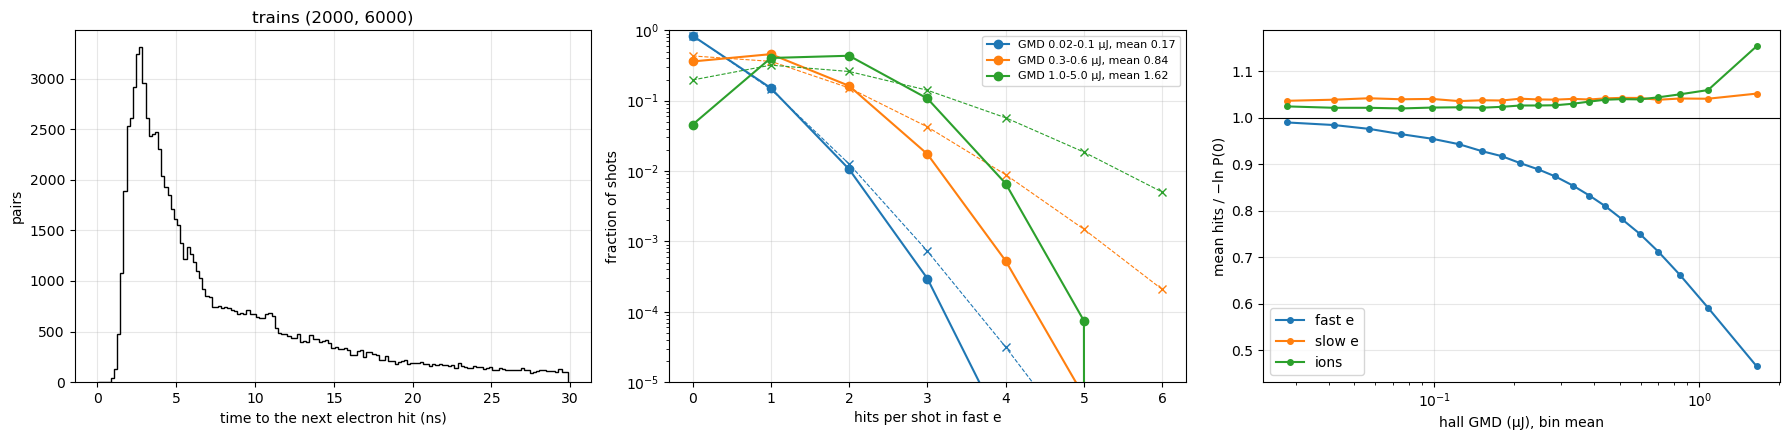

In [9]:
with h5py.File(h5_path, 'r') as f:
    te = f['tofs_e'][DT_TRAINS[0]:DT_TRAINS[1], b0:b1].astype(np.float32) / TDC_PER_NS
te = np.sort(np.where(te > 0, te, np.nan), axis=-1)                 # ns, padding (NaN) sorted last
dt = np.diff(te, axis=-1)
p0 = dict(zip(WINDOWS, binned(G, [(N[k] == 0).astype(float) for k in WINDOWS], sel, edges)))

fk = 'fast e'
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
axs[0].hist(dt[np.isfinite(dt)], bins=np.arange(0.05, 30, 0.2), histtype='step', color='k')   # 2 TDC steps (0.1 ns) per bin
axs[0].set(xlabel='time to the next electron hit (ns)', ylabel='pairs', title=f'trains {DT_TRAINS}')
for j, (lo, hi) in enumerate(((0.02, 0.1), (0.3, 0.6), (1.0, 5.0))):
    m = np.isfinite(G) & (G >= lo) & (G < hi)
    n = N[fk][m].astype(int)
    p = np.bincount(n, minlength=7)[:7] / n.size
    mu = n.mean()
    pois = np.exp(-mu) * mu ** np.arange(7) / np.cumprod(np.r_[1, np.arange(1, 7)])
    axs[1].plot(np.arange(7), p, 'o-', color=f'C{j}', label=f'GMD {lo}-{hi} µJ, mean {mu:.2f}')
    axs[1].plot(np.arange(7), pois, 'x--', color=f'C{j}', lw=0.8)
axs[1].set(xlabel=f'hits per shot in {fk}', ylabel='fraction of shots', yscale='log', ylim=(1e-5, 1))
axs[1].legend(fontsize=8)
for j, k in enumerate(WINDOWS):
    axs[2].plot(gb, nb[k] / -np.log(p0[k]), 'o-', color=f'C{j}', ms=4, label=k)
axs[2].axhline(1, color='k', lw=0.8)
axs[2].set(xlabel='hall GMD (µJ), bin mean', ylabel='mean hits / −ln P(0)', xscale='log')
axs[2].legend()
fig.tight_layout()
plt.show()

The fast peak in TOF, per µJ, for GMD ranges (trains `DT_TRAINS`); right, each divided by the 0.1-0.3 µJ range.
Losses from dead time are largest at the top of the peak. The shaded band is the fast window.

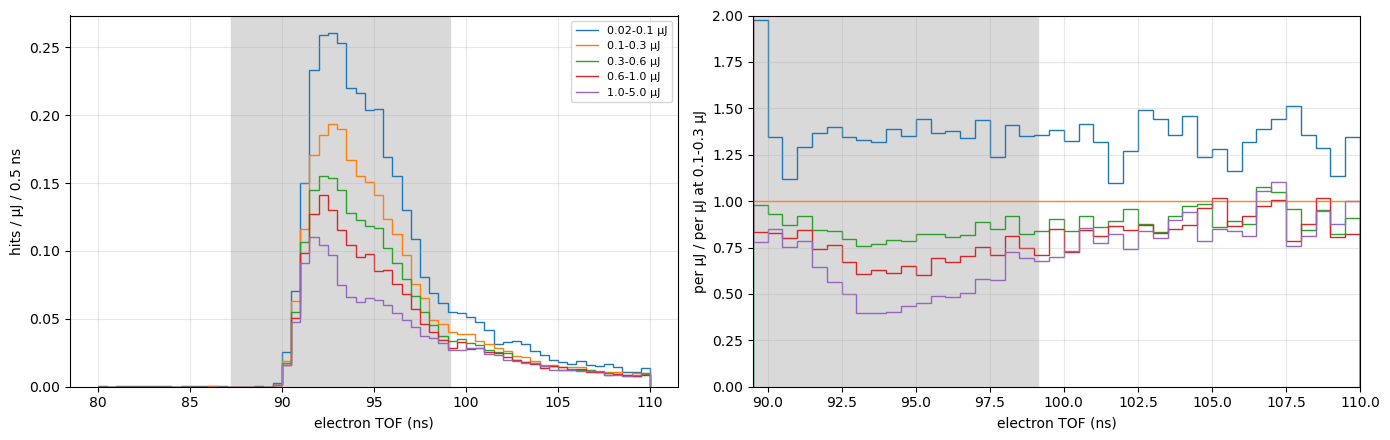

In [10]:
g_sub = G[DT_TRAINS[0]:DT_TRAINS[1]]
tof_edges = np.arange(80, 110.01, 0.5)                              # ns
ranges = ((0.02, 0.1), (0.1, 0.3), (0.3, 0.6), (0.6, 1.0), (1.0, 5.0))
spec = []
for lo, hi in ranges:
    m = np.isfinite(g_sub) & (g_sub >= lo) & (g_sub < hi)
    v = te[m].ravel()
    h, _ = np.histogram(v[np.isfinite(v)], bins=tof_edges)
    spec.append(h / g_sub[m].sum())
win_ns = calibration.tof_of_ke(np.array(WINDOWS[fk][1:])[::-1])
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for (lo, hi), s in zip(ranges, spec):
    axs[0].stairs(s, tof_edges, label=f'{lo}-{hi} µJ')
    axs[1].stairs(s / spec[1], tof_edges, label=f'{lo}-{hi} µJ')
for ax in axs:
    ax.axvspan(*win_ns, color='0.85', zorder=0)
axs[0].set(xlabel='electron TOF (ns)', ylabel='hits / µJ / 0.5 ns')
axs[1].set(xlabel='electron TOF (ns)', ylabel='per µJ / per µJ at 0.1-0.3 µJ', ylim=(0, 2), xlim=(89.5, 110))
axs[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. A third monitor: the VLS line sum

The VLS measures the same pulses with a different detector. Left: VLS sum per tunnel µJ (flat if the two are
proportional). Right: hits per VLS sum next to hits per tunnel µJ, for the same hall-GMD bins. The Gotthard saturates
near 52000 ADU per pixel; the top bins of an intense run can be affected (percentiles of `V` printed).

V percentiles (1, 50, 99, 99.9 %): [  288.  7671. 62932. 97825.]


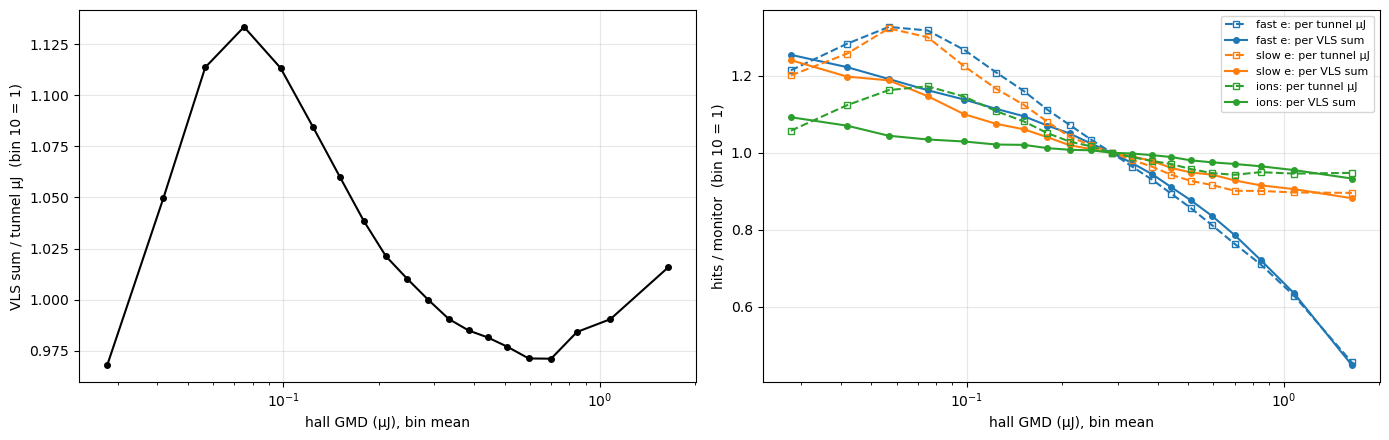

In [11]:
okv = sel & np.isfinite(V)
gbv, gtv, vb = binned(G, [G, T, V], okv, edges)
nbv = dict(zip(WINDOWS, binned(G, [N[k] for k in WINDOWS], okv, edges)))
print('V percentiles (1, 50, 99, 99.9 %):', np.percentile(V[okv], [1, 50, 99, 99.9]).round(0))
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
r = vb / gtv
axs[0].plot(gbv, r / r[REF_BIN], 'ko-', ms=4)
axs[0].set(xlabel='hall GMD (µJ), bin mean', ylabel=f'VLS sum / tunnel µJ  (bin {REF_BIN} = 1)', xscale='log')
for j, k in enumerate(WINDOWS):
    r_t, r_v = nbv[k] / gtv, nbv[k] / vb
    axs[1].plot(gbv, r_t / r_t[REF_BIN], 's--', color=f'C{j}', ms=4, mfc='none', label=f'{k}: per tunnel µJ')
    axs[1].plot(gbv, r_v / r_v[REF_BIN], 'o-', color=f'C{j}', ms=4, label=f'{k}: per VLS sum')
axs[1].set(xlabel='hall GMD (µJ), bin mean', ylabel=f'hits / monitor  (bin {REF_BIN} = 1)', xscale='log')
axs[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 6. Selection on a measured photon energy

The aggregates bin only shots with a measured photon energy (VLS line above `min_snr` of the dark estimator). Left:
fraction of shots with one per GMD bin. Right: hits per µJ of those shots / hits per µJ of all shots.

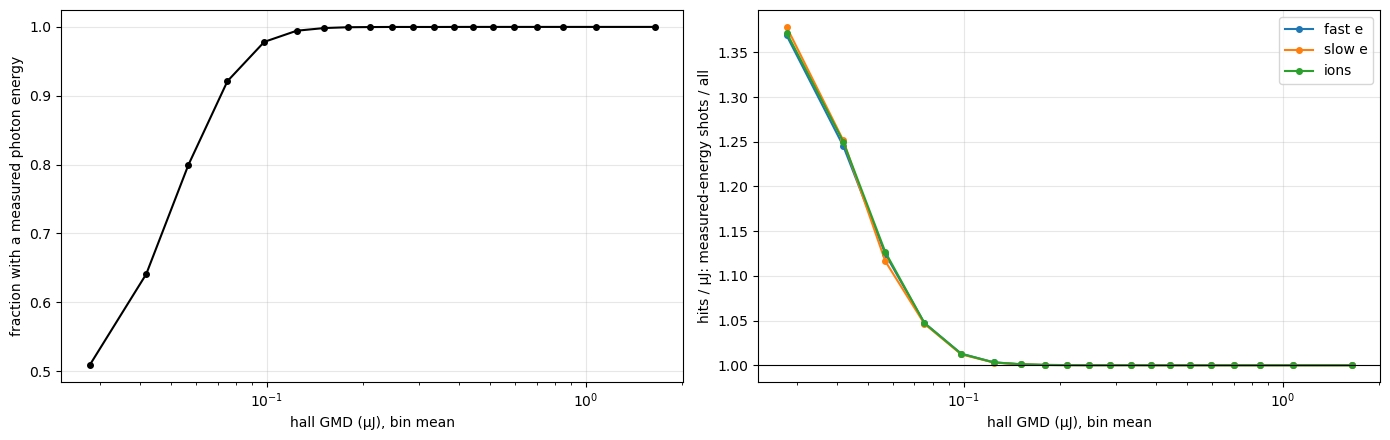

In [12]:
has_pe = np.isfinite(pe)
frac = binned(G, [has_pe.astype(float)], sel, edges)[0]
g_pe = binned(G, [G], sel & has_pe, edges)[0]
n_pe = dict(zip(WINDOWS, binned(G, [N[k] for k in WINDOWS], sel & has_pe, edges)))
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].plot(gb, frac, 'ko-', ms=4)
axs[0].set(xlabel='hall GMD (µJ), bin mean', ylabel='fraction with a measured photon energy', xscale='log')
for j, k in enumerate(WINDOWS):
    axs[1].plot(gb, (n_pe[k] / g_pe) / (nb[k] / gb), 'o-', color=f'C{j}', ms=4, label=k)
axs[1].axhline(1, color='k', lw=0.8)
axs[1].set(xlabel='hall GMD (µJ), bin mean', ylabel='hits / µJ: measured-energy shots / all', xscale='log')
axs[1].legend()
fig.tight_layout()
plt.show()

## 7. Position in the bunch train

Left: mean GMD per slot. Right: −ln P(0) per tunnel µJ in each slot, using only pulses with the tunnel GMD in `POS_G`
so that every slot is compared at the same pulse energy, divided by its median over the slots.

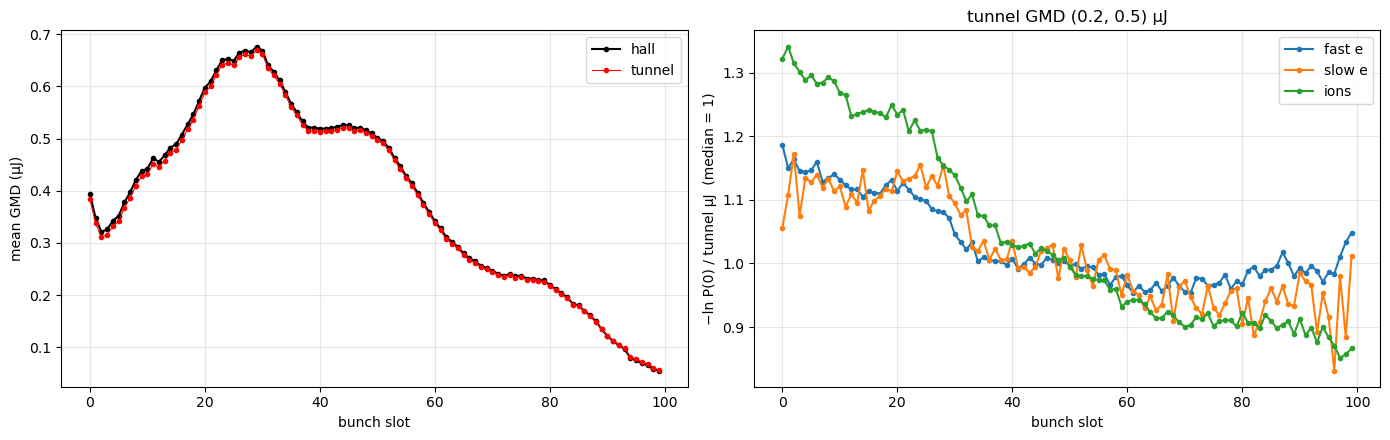

In [13]:
slots = np.arange(b0, b1)
mid = np.isfinite(T) & (T >= POS_G[0]) & (T < POS_G[1])
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].plot(slots, np.nanmean(G, 0), 'k.-', label='hall')
axs[0].plot(slots, np.nanmean(T, 0), 'r.-', lw=0.8, label='tunnel')
axs[0].set(xlabel='bunch slot', ylabel='mean GMD (µJ)')
axs[0].legend()
for j, k in enumerate(WINDOWS):
    y = np.array([-np.log(np.mean(N[k][mid[:, s], s] == 0)) / T[mid[:, s], s].mean() for s in range(b1 - b0)])
    axs[1].plot(slots, y / np.median(y), '.-', color=f'C{j}', label=k)
axs[1].set(xlabel='bunch slot', ylabel=f'−ln P(0) / tunnel µJ  (median = 1)', title=f'tunnel GMD {POS_G} µJ')
axs[1].legend()
fig.tight_layout()
plt.show()

## 8. Step by step

Yield per monitor for each window, same hall-GMD bins: mean hits per hall µJ (as the aggregates), per tunnel µJ
(section 3), the dead-time-free −ln P(0) per tunnel µJ (section 4), and −ln P(0) per VLS sum (section 5).

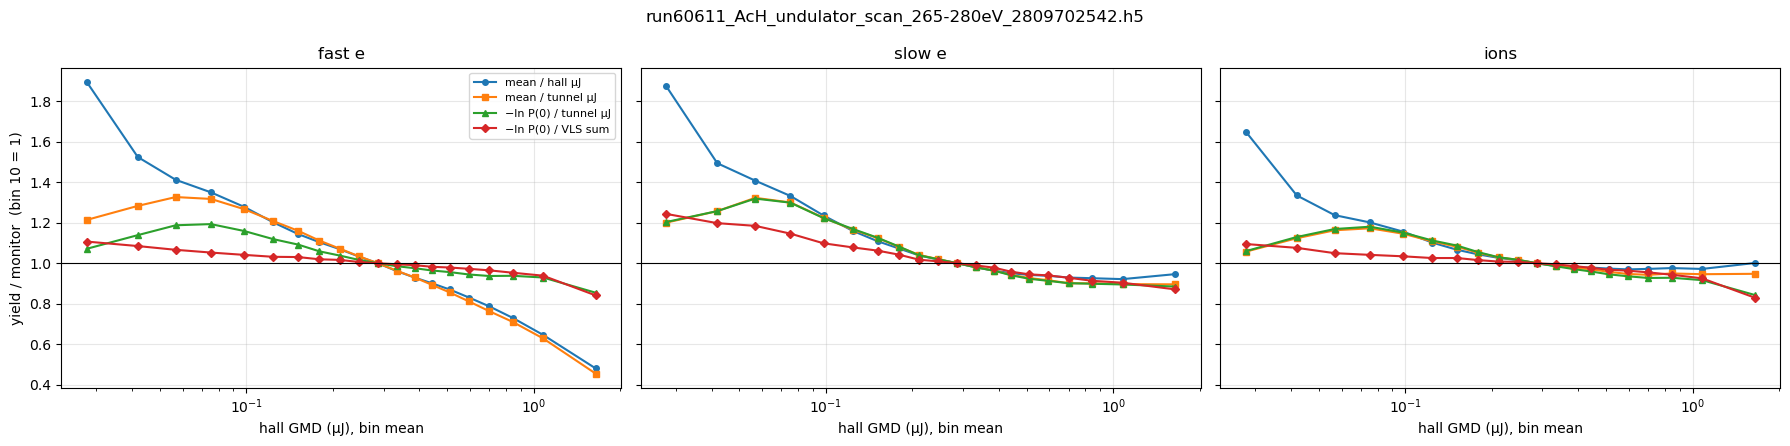

In [14]:
fig, axs = plt.subplots(1, len(WINDOWS), figsize=(6 * len(WINDOWS), 4.5), sharey=True)
for ax, k in zip(axs, WINDOWS):
    m8, p8 = binned(G, [N[k], (N[k] == 0).astype(float)], okv, edges)
    curves = [('mean / hall µJ', m8 / gbv), ('mean / tunnel µJ', m8 / gtv),
              ('−ln P(0) / tunnel µJ', -np.log(p8) / gtv), ('−ln P(0) / VLS sum', -np.log(p8) / vb)]
    for (lab, c), st in zip(curves, ('o-', 's-', '^-', 'D-')):
        ax.plot(gbv, c / c[REF_BIN], st, ms=4, label=lab)
    ax.axhline(1, color='k', lw=0.8)
    ax.set(xlabel='hall GMD (µJ), bin mean', title=k, xscale='log')
axs[0].set_ylabel(f'yield / monitor  (bin {REF_BIN} = 1)')
axs[0].legend(fontsize=8)
fig.suptitle(h5_path.name)
fig.tight_layout()
plt.show()